# Option 2: Does a Neural Network Beat a Classical Model?

## Adult Census Income Classification
**Scenario.** A public agency wants to flag households likely to be in a higher-income bracket (>50K) so a benefit or outreach programme can be targeted. Option A is a simple, explainable model (logistic regression); option B is a small neural network that may or may not be more accurate.

**Central question.** Does the neural network perform better, and is its extra complexity worthwhile?

**Machine Learning Module Final Project**

This project compares two approaches to the same classification problem using the Adult Census Income dataset:

- Logistic Regression
- A small Neural Network

The goal is to determine whether the neural network provides a meaningful improvement in predictive performance compared with a simpler and more interpretable classical model.


## 1. Imports and Setup

The analysis uses Python and the following libraries:

- `pandas` and `numpy` for data manipulation
- `matplotlib` and `seaborn` for visualization
- `scikit-learn` for preprocessing, model training, cross-validation and evaluation






In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)


RANDOM_STATE = 42


## 2. Dataset

### Loading the Adult Census Income Dataset




In [2]:
# Adult Census Income 
adult_income = fetch_openml('adult', version=2, as_frame=True)
df = adult_income.frame.copy()
print(df.shape)
df.head()

(48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,class
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


In [3]:
df.info() # inspect the data types and missing values

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             48842 non-null  int64   
 1   workclass       46043 non-null  category
 2   fnlwgt          48842 non-null  int64   
 3   education       48842 non-null  category
 4   education-num   48842 non-null  int64   
 5   marital-status  48842 non-null  category
 6   occupation      46033 non-null  category
 7   relationship    48842 non-null  category
 8   race            48842 non-null  category
 9   sex             48842 non-null  category
 10  capital-gain    48842 non-null  int64   
 11  capital-loss    48842 non-null  int64   
 12  hours-per-week  48842 non-null  int64   
 13  native-country  47985 non-null  category
 14  class           48842 non-null  category
dtypes: category(9), int64(6)
memory usage: 2.7 MB


### Quick Exploration


In [4]:
y = (df['class'] == '>50K').astype(int) # Target variable
X = df.drop(columns=['class']) # Input features

print(y.value_counts()) # Target class: 1 = income >50K, 0 = income <=50K
print('\nIncome earning >50K: {:.1%}'.format(y.mean()))
print('\nMissing values per column:')
print(X.isna().sum()[X.isna().sum() > 0])

class
0    37155
1    11687
Name: count, dtype: int64

Income earning >50K: 23.9%

Missing values per column:
workclass         2799
occupation        2809
native-country     857
dtype: int64


**Comments:**
- The classes are imbalanced (23.9% are >50K), so accuracy alone would be misleading: always predicting `<=50K` already scores about 76.1%. That is why F1 on the `>50K` class is the main metric.
- `fnlwgt` is a survey sampling weight, not a household characteristic, so it is dropped.
- `education` is a text version of `education-num`, so it is dropped to avoid duplicate information.

In [5]:
X = X.drop(columns=['fnlwgt', 'education'])

## 3. Train / Test Split and Preprocessing Pipeline

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

X_train, X_test = X_train.reset_index(drop=True), X_test.reset_index(drop=True)
y_train, y_test = y_train.reset_index(drop=True), y_test.reset_index(drop=True)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (39073, 12)  Test: (9769, 12)


In [7]:
# Split features into numeric and categorical columns for preprocessing
num_cols = X_train.select_dtypes(include='number').columns.tolist()
cat_cols = X_train.select_dtypes(exclude='number').columns.tolist()
print('Numeric:', num_cols)
print('Categorical:', cat_cols)

# Numeric features: impute missing values with median, then scale to mean=0, std=1
numeric_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])

# Categorical features: impute missing values with most frequent, then one-hot encode
categorical_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', min_frequency=20)),
])

# Combine numeric and categorical preprocessing into a single transformer
preprocess = ColumnTransformer([
    ('num', numeric_pipe, num_cols),
    ('cat', categorical_pipe, cat_cols),
])

Numeric: ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical: ['workclass', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


## 4. Logistic Regression with Cross-Validation

In [8]:
log_reg = Pipeline([
    ('prep', preprocess),
    ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ['f1', 'precision', 'recall', 'accuracy']

lr_cv = cross_validate(log_reg, X_train, y_train, cv=cv, scoring=scoring)
lr_cv_summary = pd.DataFrame({m: [lr_cv['test_' + m].mean(), lr_cv['test_' + m].std()] for m in scoring},
                             index=['mean', 'std']).T
lr_cv_summary.round(3)

,mean,std
f1,0.658,0.008
precision,0.731,0.016
recall,0.598,0.005
accuracy,0.851,0.005


### Prediction

**Expected result.** I expect the neural network's F1 to be about the same as logistic regression's, with at most a small improvement. 

**Why:**
- Neural networks can learn nonlinear relationships and interactions between age, education, working hours and employment categories.
- However, the data are tabular, with only about 12 features after dropping `fnlwgt` and `education`. On small tabular problems like this, simple models usually come close to the best achievable performance, and neural networks tend to have no clear edge.
- Most features are categorical and become one-hot columns. A linear model handles these well, since each category gets its own weight.

**Expected differences in errors.** Logistic regression's precision (0.73) is clearly higher than its recall (0.60), so it misses a lot of true >50K households (false negatives) and is more careful about flagging households (fewer false positives). I expect the network to show a similar pattern, since both use the same default 0.5 threshold on an imbalanced target. If the network differs, I expect it to find a few more of the high-income households through interactions (slightly higher recall), at the cost of a few more false positives (slightly lower precision), leaving F1 roughly unchanged.

**What would justify the extra complexity.** Given the CV standard deviation of about 0.008, I would want the network's F1 to be higher by at least 2 percentage points (about 0.02), and consistently so across folds and on the test set, before considering it worthwhile. A gain of that size would have to be weighed against the loss of explainability, longer training time and tuning effort, and the added difficulty of auditing fairness across sex, race and nationality. A gain under 1 point would not justify replacing a model that can be explained directly to the public.

## 5. Neural network

In [9]:
nn = Pipeline([
    ('prep', preprocess),
    ('model', MLPClassifier(hidden_layer_sizes=(32, 16), activation='relu', alpha=1e-3,
                            early_stopping=True, validation_fraction=0.1, n_iter_no_change=10,
                            max_iter=300, random_state=RANDOM_STATE)),
])

nn_cv = cross_validate(nn, X_train, y_train, cv=cv, scoring=scoring)
nn_cv_summary = pd.DataFrame({m: [nn_cv['test_' + m].mean(), nn_cv['test_' + m].std()] for m in scoring},
                             index=['mean', 'std']).T

cv_compare = pd.concat({'LogReg': lr_cv_summary, 'NeuralNet': nn_cv_summary}, axis=1)
cv_compare.round(3)

LogReg        NeuralNet       
            mean    std      mean    std
f1         0.658  0.008     0.672  0.009
precision  0.731  0.016     0.737  0.023
recall     0.598  0.005     0.619  0.015
accuracy   0.851  0.005     0.856  0.005

### Cross-validation findings

| Metric | LogReg (mean ± std) | NeuralNet (mean ± std) | Difference |
|---|---|---|---|
| F1 | 0.658 ± 0.008 | 0.672 ± 0.009 | +0.014 |
| Precision | 0.731 ± 0.016 | 0.737 ± 0.023 | +0.006 |
| Recall | 0.598 ± 0.005 | 0.619 ± 0.015 | +0.021 |
| Accuracy | 0.851 ± 0.005 | 0.856 ± 0.005 | +0.005 |

**Overall.** The neural network scores slightly higher on every metric, but the gains are small. Its F1 is 1.4 percentage points higher (0.672 vs 0.658), which is only about 1.5 times the fold-to-fold standard deviation. That is a modest, probably real, but not decisive improvement.

**Where the gain comes from.** Almost all of it is recall (+2.1 points). The network finds more of the truly high-income households. Precision barely moves (+0.6 points, well inside the noise, since the standard deviations are 1.6 to 2.3 points). Accuracy rises by only 0.5 points, which is about one standard deviation, and accuracy is the least informative metric here because of the class imbalance.

**Comparison with my prediction.** I predicted roughly equal performance with at most a small gain, and a similar precision/recall pattern. That was largely right: both models are precision-heavy (precision about 0.73 vs recall about 0.60 to 0.62), and the gain is small. I also expected the extra recall to come with lower precision, but precision stayed flat, so the network's extra recall was nearly free in terms of false positives.

**Is it worth the complexity?** Against the threshold I set in advance (a consistent gain of at least about 2 F1 points), the network falls short at 1.4 points. The most plausible explanation is that it captures some interactions between features that a linear model cannot, but the effect is small because most of the signal is already captured by the main effects. The network is also noisier on precision and recall (std up to 0.023), so its behaviour is less stable across folds.


## 6. Final comparison on the test set

In [10]:
results, preds = {}, {}
for name, model in [('LogReg', log_reg), ('NeuralNet', nn)]:
    t0 = time.time()
    model.fit(X_train, y_train)
    fit_time = time.time() - t0
    y_pred = model.predict(X_test)
    preds[name] = y_pred
    results[name] = {
        'F1': f1_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'Accuracy': accuracy_score(y_test, y_pred),
        'Fit time (s)': fit_time,
    }

test_results = pd.DataFrame(results).T
test_results.round(3)

,F1,Precision,Recall,Accuracy,Fit time (s)
LogReg,0.659,0.739,0.595,0.853,0.268
NeuralNet,0.682,0.739,0.633,0.859,1.470


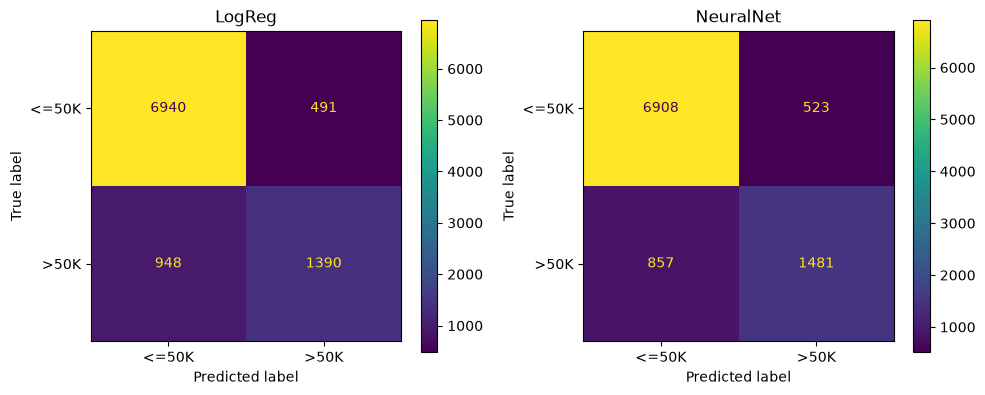

LogReg: TP=1390  FP=491  FN=948  TN=6940
NeuralNet: TP=1481  FP=523  FN=857  TN=6908


In [11]:
# Confusion matrices for the two models
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=['<=50K', '>50K']).plot(ax=ax, colorbar=True,values_format='d')
    ax.set_title(name)
plt.tight_layout()
plt.show()

for name, y_pred in preds.items():
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    print(f'{name}: TP={tp}  FP={fp}  FN={fn}  TN={tn}')

In [12]:
for name, y_pred in preds.items():
    print('=' * 10, name, '=' * 10)
    print(classification_report(y_test, y_pred, target_names=['<=50K', '>50K'], digits=3))

========== LogReg ==========
              precision    recall  f1-score   support

       <=50K      0.880     0.934     0.906      7431
        >50K      0.739     0.595     0.659      2338

    accuracy                          0.853      9769
   macro avg      0.809     0.764     0.782      9769
weighted avg      0.846     0.853     0.847      9769

========== NeuralNet ==========
              precision    recall  f1-score   support

       <=50K      0.890     0.930     0.909      7431
        >50K      0.739     0.633     0.682      2338

    accuracy                          0.859      9769
   macro avg      0.814     0.782     0.796      9769
weighted avg      0.854     0.859     0.855      9769



## 7. Ethical considerations
### 7.1 Fairness across sex, race and nationality

In [13]:
def group_report(X_te, y_true, y_pred, col, min_n=30):
    rows = []
    for g in X_te[col].dropna().unique():
        m = (X_te[col] == g).values
        if m.sum() < min_n:
            continue
        tn, fp, fn, tp = confusion_matrix(y_true[m], y_pred[m], labels=[0, 1]).ravel()
        rows.append({
            col: g, 'n': int(m.sum()),
            'base_rate': y_true[m].mean(),
            'selection_rate': y_pred[m].mean(),
            'TPR': tp / (tp + fn) if (tp + fn) else np.nan,
            'FPR': fp / (fp + tn) if (fp + tn) else np.nan,
            'F1': f1_score(y_true[m], y_pred[m], zero_division=0),
        })
    return pd.DataFrame(rows).sort_values('n', ascending=False).set_index(col)

# Nationality has ~40 values, so group into US / non-US / unknown
X_eval = X_test.copy()
X_eval['nationality'] = np.where(X_eval['native-country'].isna(), 'Unknown',
                          np.where(X_eval['native-country'] == 'United-States', 'US', 'Non-US'))

yt = y_test.values
for col in ['sex', 'race', 'nationality']:
    for name in preds:
        print(f'\n--- {col} | {name} ---')
        display(group_report(X_eval, yt, preds[name], col).round(3))


--- sex | LogReg ---


,n,base_rate,selection_rate,TPR,FPR,F1
sex,,,,,,
Male,6510,0.304,0.251,0.608,0.095,0.667
Female,3259,0.111,0.076,0.518,0.021,0.613



--- sex | NeuralNet ---


,n,base_rate,selection_rate,TPR,FPR,F1
sex,,,,,,
Male,6510,0.304,0.268,0.648,0.101,0.689
Female,3259,0.111,0.080,0.551,0.022,0.639



--- race | LogReg ---


...

,n,base_rate,selection_rate,TPR,FPR,F1
race,,,,,,
White,8312,0.253,0.220,0.641,0.077,0.686
Black,968,0.133,0.092,0.550,0.021,0.651
Asian-Pac-Islander,311,0.264,0.251,0.646,0.109,0.662
Amer-Indian-Eskimo,96,0.135,0.052,0.308,0.012,0.444
Other,82,0.122,0.085,0.500,0.028,0.588



--- nationality | LogReg ---


,n,base_rate,selection_rate,TPR,FPR,F1
nationality,,,,,,
US,8731,0.243,0.196,0.599,0.067,0.662
Non-US,862,0.196,0.153,0.550,0.056,0.618
Unknown,176,0.250,0.193,0.568,0.068,0.641



--- nationality | NeuralNet ---


,n,base_rate,selection_rate,TPR,FPR,F1
nationality,,,,,,
US,8731,0.243,0.210,0.640,0.072,0.687
Non-US,862,0.196,0.152,0.550,0.055,0.620
Unknown,176,0.250,0.210,0.636,0.068,0.691


### Fairness findings

**Sex.** This is the clearest and most consistent gap, and it is nearly identical in both models.

| | LogReg (Male / Female) | NeuralNet (Male / Female) |
|---|---|---|
| TPR | 0.608 / 0.518 (gap 0.090) | 0.648 / 0.551 (gap 0.097) |
| FPR | 0.095 / 0.021 (gap 0.074) | 0.101 / 0.022 (gap 0.079) |
| Selection rate | 0.251 / 0.076 | 0.268 / 0.080 |
| F1 | 0.667 / 0.613 | 0.689 / 0.639 |

Women who are truly high-income are found less often than men (about 9-10 points lower TPR), and women are also much less likely to be wrongly flagged (FPR about 2% vs 10%). Part of this reflects the data: only 11% of women are in the >50K class vs 30% of men. But the models do not just mirror that. Men are selected about 3.3 times as often as women, while the true base rates differ by about 2.7 times, so both models slightly amplify the existing gap. The neural network does not fix this: its gaps are marginally wider than logistic regression's.

**Race.** Gaps are larger here, and the neural network changes them more.
- With logistic regression, the TPR for Black households (0.450) is 15 points below White (0.605). The neural network lifts it to 0.550 and cuts the gap to about 9 points, with Black FPR essentially unchanged (0.023 vs 0.021). The F1 gap between White and Black households shrinks from 0.103 to 0.035. This is the one place where the network is clearly fairer.
- Asian-Pac-Islander households have the highest FPR in both models (about 0.11 vs 0.07 for White), meaning they are the most likely to be wrongly flagged as higher-income.
- The Amer-Indian-Eskimo (n=96) and Other (n=82) groups have the lowest TPR (0.31 and 0.40-0.50) but are too small to interpret. With a base rate of about 13%, the first group has only about 13 true positives, so one household changes TPR by about 8 points. The identical row for Amer-Indian-Eskimo in both models suggests the same few cases are being missed. I treat these two groups as inconclusive, not as evidence of discrimination.

**Nationality.** Here the neural network widens the gap.
- Logistic regression's TPR is 0.599 for US vs 0.550 for non-US households (gap 0.049). The neural network raises the US TPR to 0.640 but leaves non-US at 0.550, so the gap grows to 0.090. The F1 gap grows from 0.044 to 0.067.
- FPRs are similar across groups (0.055-0.072) in both models. The "Unknown" group (n=176) is small and noisy.

**Do the models differ, and does the network narrow or widen gaps?**
Overall, the network's improvement is not spread evenly. It gives a clear boost to the majority groups (men, White, US-born) and leaves non-US households untouched. Sex gaps are about the same, race gaps (White vs Black) narrow, and nationality gaps widen. So the network is not uniformly fairer or less fair. It shifts the gaps around, and any adoption decision would need a fairness audit of its own.

**Limitations.** These are single test-split estimates with no confidence intervals. Small groups (Other, Amer-Indian-Eskimo, Unknown) are unreliable. Nationality is coarsely grouped into US / non-US. And a model cannot satisfy every fairness definition at once when base rates differ between groups, so choosing which gap matters most (for example, equal TPR for people who truly qualify) is a policy decision, not a purely technical one.

### 7.2 Transparency
Logistic regression coefficients can be read directly and explained to the public. The neural network has no comparably simple explanation. Below are the features that push a household toward or away from the >50K prediction in the logistic regression.

In [14]:
feat_names = log_reg.named_steps['prep'].get_feature_names_out()
coefs = pd.Series(log_reg.named_steps['model'].coef_[0], index=feat_names).sort_values()
print('Strongest negative (towards <=50K):'); print(coefs.head(8).round(2))
print('\nStrongest positive (towards >50K):'); print(coefs.tail(8).round(2))

Strongest negative (towards <=50K):
cat__native-country_Columbia             -1.32
cat__occupation_Priv-house-serv          -1.27
cat__marital-status_Never-married        -1.22
cat__native-country_South                -1.08
cat__occupation_Farming-fishing          -0.96
cat__sex_Female                          -0.93
cat__native-country_Dominican-Republic   -0.91
cat__occupation_Other-service            -0.87
dtype: float64

Strongest positive (towards >50K):
cat__relationship_Wife                    0.73
num__education-num                        0.77
cat__occupation_Exec-managerial           0.80
cat__native-country_England               0.81
cat__native-country_France                0.85
cat__marital-status_Married-AF-spouse     1.18
cat__marital-status_Married-civ-spouse    1.61
num__capital-gain                         2.25
dtype: float64


## 8. Final interpretation

### 8.1 Performance

| | CV F1 (mean ± std) | Test F1 | Test precision | Test recall | Test accuracy |
|---|---|---|---|---|---|
| Logistic regression | 0.658 ± 0.008 | 0.659 | 0.739 | 0.595 | 0.853 |
| Neural network | 0.672 ± 0.009 | 0.682 | 0.739 | 0.633 | 0.859 |
| Difference | +0.014 | +0.023 | 0.000 | +0.038 | +0.006 |

The neural network is ahead on both CV and the held-out test set, so the direction of the result is consistent. The logistic regression test F1 (0.659) matches its CV estimate (0.658), which suggests the pipeline has no leakage and the estimates are reliable. The network's test F1 (0.682) is a little above its CV estimate (0.672), by about one CV standard deviation, which is plausible sampling variation.


### 8.2 Confusion matrices

| | TP | FP | FN | TN |
|---|---|---|---|---|
| Logistic regression | 1390 | 491 | 948 | 6940 |
| Neural network | 1481 | 523 | 857 | 6908 |
| Change | +91 | +32 | −91 | −32 |

The test set has 2,338 truly high-income households and 7,431 lower-income ones. Both models make the same kind of error: they miss more high-income households than they wrongly flag. Logistic regression misses 948 (40.5%) and the network misses 857 (36.7%). Both models are conservative, with precision of about 0.74 and recall of about 0.60-0.63.

The network shifts this a little. It finds 91 more high-income households at the cost of 32 more false flags, so about 2.8 extra correct flags for every extra wrong one. Precision stays at 0.739 in both models, so the extra recall costs almost nothing in precision. The net effect is 59 more correct predictions out of 9,769 (0.6 points of accuracy). The network does not change which kind of mistake dominates. It finds slightly more of the households that logistic regression misses.

### 8.3 Prediction vs reality

My prediction was that the network would perform about the same as logistic regression, with at most a small improvement, and that any difference would show up as slightly higher recall. This was mostly right. The gain is small and it comes almost entirely from recall (CV +2.1 points, test +3.8 points). Two details were off. I expected the extra recall to come with lower precision, but precision stayed flat. And I expected F1 to be roughly unchanged, whereas it rose by 1.4 points in CV and 2.3 on the test set, which is more than "roughly unchanged".

I also set a threshold in advance: the network would need to be at least 2 F1 points better, consistently across folds and on the test set. The test gap (+2.3) clears that bar, but the CV gap (+1.4) does not. So the network meets my criterion on one measure and misses it on the other. That tells me this kind of data, with about a dozen mostly categorical features and a large sample, is mostly well described by linear effects. The network picks up some interactions (such as age combined with marital status or hours worked), but there is not much extra structure to find.

### 8.4 Cost of complexity

- **Training time.** The network took 1.5 s against 0.27 s for logistic regression, about 5.7 times longer. At this scale both are trivial, so training cost is not a real argument either way. It would matter with larger data or repeated retraining and auditing.
- **Tuning effort.** Logistic regression has essentially one setting (regularisation strength). The network has architecture, regularisation, learning rate, early stopping and more. I used one reasonable configuration without tuning, so its true ceiling is unknown, and a tuned logistic regression (for example with interaction terms) might also close the gap.
- **Reproducibility.** Logistic regression gives the same solution every time. The network depends on random initialisation and the random validation split used for early stopping, so results can shift between runs. It also had a higher CV standard deviation for precision (0.023 vs 0.016) and recall (0.015 vs 0.005), so it is less stable across folds.
- **Explainability.** Logistic regression coefficients can be read directly and explained to the public ("each additional year of education raises the odds by X"). The network offers no comparably simple explanation, and post-hoc tools only approximate its behaviour. For a public agency whose decisions affect people's benefits, this matters because people should be able to understand and contest a decision.

### 8.5 Fairness

**Sex.** The gap is large and almost identical in both models. True positive rates are 0.608 (men) vs 0.518 (women) for logistic regression and 0.648 vs 0.551 for the network. Women are also much less likely to be wrongly flagged (FPR about 2% vs 10%). Part of this reflects the data, since only 11% of women are in the >50K class against 30% of men. But the models amplify it slightly: men are selected about 3.3 times as often as women while the base rates differ by about 2.7 times. The network does not improve this, and its gaps are marginally wider (TPR gap 0.097 vs 0.090).

**Race.** The network narrows the White vs Black gap. Black households' TPR rises from 0.450 to 0.550, the F1 gap between White and Black households shrinks from 0.103 to 0.035, and the Black FPR stays about the same (0.023 vs 0.021). Asian-Pacific-Islander households have the highest FPR in both models (about 0.11 vs 0.07 for White), so they are the most likely to be wrongly flagged as higher-income. The Amer-Indian-Eskimo (n=96) and Other (n=82) groups are too small to interpret: with about 13 true positives in the first group, one household changes TPR by about 8 points.

**Nationality.** The network widens the gap. The TPR gap between US and non-US households grows from 0.049 to 0.090 because the network improves US-born households (0.599 to 0.640) and leaves non-US households unchanged (0.550). The F1 gap grows from 0.044 to 0.067.

**Overall.** Neither model is uniformly fairer. The network helps some groups (Black households) but mostly benefits the majority groups, and does not improve non-US households at all. 

### 8.6 Recommendation

I would recommend **logistic regression** to the agency.

- The network's advantage is real but small: +1.4 F1 points in CV, +2.3 on the test set, and about 91 more high-income households found out of 2,338. It does not change the dominant error type, and precision is identical.
- Both models miss a large share of higher-income households (about 37-40%). If missing eligible households is the main cost, the more promising lever may be the decision threshold rather than the model type. T
- The network's fairness profile is mixed and it widens the nationality gap, so adopting it would require its own audit.
- A model that decisions can be explained and challenged with is worth more than a gain of this size when it affects people's access to a benefit.

I would change my mind if:
1. The network's improvement were consistent across folds, with a bootstrap interval clearly above zero, and larger than about 2-3 F1 points after reasonable tuning of both models.
2. A fairness audit showed that the network does not widen gaps for women or non-US households, and the groups affected are checked with enough data.
3. The agency had a way to explain individual decisions (for example, a validated explanation method) and a process for people to contest them.
4. The cost of missed eligible households were high enough that the extra recall justified the added opacity.

Without those conditions, the simpler, transparent model is the better choice.

## 9. Reflection and improvements

***What worked well:*** 
Pipeline-based preprocessing handled mixed data types and protected cross-validation from leakage. Stratification preserved the minority class. F1 and the confusion matrices made the precision–recall trade-off easier to assess than accuracy alone.

***What was difficult:*** 
The two models have different training dynamics, and a larger number of parameters does not automatically produce a policy-relevant improvement. Subgroup comparisons are difficult when countries have very few positive examples. Logistic-regression coefficients are easier to inspect, but overlapping inputs complicate interpretation.

***What I would improve:*** 
Repeat the neural-network experiment across training seeds and use the same cross-validation folds for both models. Tune each model with an explicit, comparable search budget on training data only; evaluate any selected models on a fresh holdout. Choose a threshold using validation F1 or policy costs, compare calibration, obtain uncertainty intervals for sufficiently supported subgroup rates, and examine intersectional fairness. Investigate fnlwgt and redundant education features through training-only ablations. For a real public agency, obtain current, representative household data and define the action and ethical requirements before fitting models.
